# 15 · The test period (work package 7)

**Work package 7** of the [implementation plan](../../research/implementation_plan.md). The models were frozen in
commit `856cbfa` (tag `test-freeze`) and scored once on the 14 test points (13 August – 10 September 2026) by
`src/scripts/run_test.py`. The results were committed right after the run (`b619c62`). This notebook reads them
and analyses them; it does not choose or change any model.

- **Primary model:** the LambdaMART ranker (chosen on Dev B by the rule of implementation plan 9.1).
- **Secondary models:** the untimed fixed blend (notebook 11), the time-weighted blend (notebook 12), and the
  boosted-trees and logistic-regression rankers (notebook 14).
- **Success criterion:** the mean paired difference in recall@10 between the primary model and the baseline over
  the 14 test points is positive, and its 95% bootstrap interval excludes zero.

Sections 1–4 read `results/test/` only. The error analysis (section 5) needs the primary model's lists, which the
run did not save: they are made again with the frozen model, and a check confirms that they give exactly the
recall that was scored.

In [1]:
import json
import sys

sys.path.append("../scripts")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import error_analysis as ea
import plots
import protocol as pc
import ranker as rk
import run_test
import stats
import token_data as td

plots.style()
pd.set_option("display.float_format", "{:,.4f}".format)
TEST = pc.RESULTS_DIR / "test"
OUT = pc.RESULTS_DIR / "wp7"
OUT.mkdir(parents=True, exist_ok=True)

run = json.loads((TEST / "run.json").read_text())
per_point = pd.read_csv(TEST / "per_point.csv", parse_dates=["point"])
compare = pd.read_csv(TEST / "compare.csv")
by_group = pd.read_csv(TEST / "by_group.csv")
frozen = json.loads((pc.RESULTS_DIR.parent / "configs" / "frozen.json").read_text())
PRIMARY = frozen["primary"]
BASELINE = "popularity (baseline)"
print(f"Scored from commit {run['commit'][:8]}, {run['started'][:16]} to {run['finished'][:16]} UTC")

Scored from commit 0e1a49e0, 2026-11-23T13:02 to 2026-11-23T14:07 UTC


## 1. The verdict

In [2]:
low, high = run["interval"]
print(f"Primary model: {run['primary']}")
print(f"Mean difference in recall@10 against the baseline: {run['mean_difference']:+.4f}")
print(f"95% bootstrap interval over the 14 points: [{low:+.4f}, {high:+.4f}]")
print(f"Success criterion: {'MET' if run['success'] else 'NOT met'}")

Primary model: ranker: lambdamart
Mean difference in recall@10 against the baseline: +0.0458
95% bootstrap interval over the 14 points: [+0.0381, +0.0551]
Success criterion: MET


Every model against the baseline on the 14 test points:

In [3]:
compare

,model,points,mean,lowest,highest,mean_difference,interval_low,interval_high,wins,sign_test_p
0,popularity (baseline),14,0.1084,0.0886,0.1474,NaN,NaN,NaN,NaN,NaN
1,ranker: lambdamart,14,0.1542,0.1267,0.1932,0.0458,0.0381,0.0551,14 of 14,0.0001
2,ranker: gbdt,14,0.1437,0.1213,0.1785,0.0354,0.0291,0.0436,14 of 14,0.0001
3,ranker: logistic,14,0.1375,0.1218,0.1705,0.0292,0.0233,0.0353,14 of 14,0.0001
4,fixed blend,14,0.1528,0.1342,0.1960,0.0445,0.0385,0.0508,14 of 14,0.0001
5,time-weighted blend,14,0.1506,0.1285,0.1865,0.0422,0.0352,0.0492,14 of 14,0.0001


## 2. Point by point

The 14 paired differences of the primary model (implementation plan, open point 11.5: a bootstrap over 14 points
is rough, so the differences themselves are always shown).

In [4]:
recall = per_point.pivot_table(index="point", columns="model", values="recall")
differences = pd.DataFrame({
    "baseline": recall[BASELINE],
    "primary": recall[PRIMARY],
    "difference": recall[PRIMARY] - recall[BASELINE],
})  # fmt: skip
differences.index = differences.index.strftime("%d %b")
differences

,baseline,primary,difference
point,,,
13 Aug,0.0971,0.1363,0.0392
15 Aug,0.0886,0.1432,0.0546
17 Aug,0.1045,0.1460,0.0415
19 Aug,0.1070,0.1518,0.0448
21 Aug,0.1031,0.1467,0.0436
23 Aug,0.0896,0.1416,0.0520
25 Aug,0.1003,0.1924,0.0921
27 Aug,0.1474,0.1932,0.0458
29 Aug,0.1363,0.1614,0.0250


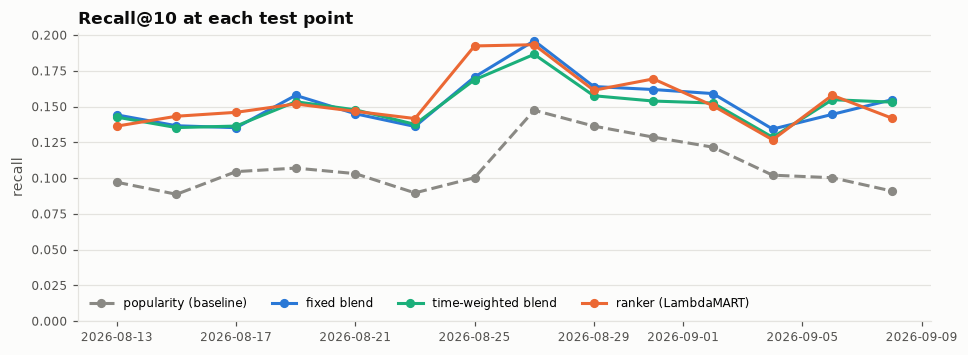

In [5]:
shown = {
    BASELINE: per_point[per_point["model"] == BASELINE],
    "fixed blend": per_point[per_point["model"] == "fixed blend"],
    "time-weighted blend": per_point[per_point["model"] == "time-weighted blend"],
    "ranker (LambdaMART)": per_point[per_point["model"] == PRIMARY],
}
fig, ax = plt.subplots(figsize=(10, 3.4))
plots.per_point_lines(ax, shown)
ax.set_title("Recall@10 at each test point")
ax.set_ylim(bottom=0)
plt.show()

## 3. Does the ranker beat the fixed combinations?

Research question 4, on the test points: the primary model against each fixed blend, paired by point.

In [6]:
rows = []
for reference in ["fixed blend", "time-weighted blend"]:
    d = stats.paired_differences(per_point[per_point["model"] == PRIMARY], per_point[per_point["model"] == reference])
    low_d, high_d = stats.bootstrap_over_points(d)
    rows.append({"against": reference, "mean_difference": d.mean(), "interval_low": low_d, "interval_high": high_d,
                 "wins": f"{stats.sign_test(d)['wins']} of {len(d)}"})  # fmt: skip
ranker_vs_fixed = pd.DataFrame(rows)
ranker_vs_fixed.to_csv(OUT / "ranker_vs_fixed_test.csv", index=False)
ranker_vs_fixed

,against,mean_difference,interval_low,interval_high,wins
0,fixed blend,0.0014,-0.0035,0.0066,7 of 14
1,time-weighted blend,0.0036,-0.0007,0.0083,8 of 14


**Across periods.** Mean recall@10 of each model on Dev B (where the primary model was chosen) and on the test.

In [7]:
dev_b = {
    BASELINE: pc.RESULTS_DIR / "wp2" / "baseline_dev.csv",
    "fixed blend": pc.RESULTS_DIR / "wp3" / "fixed_blend_dev_b.csv",
    "time-weighted blend": pc.RESULTS_DIR / "wp4" / "time_weighted_blend_dev_b.csv",
    "ranker: gbdt": pc.RESULTS_DIR / "wp6" / "ranker_gbdt_dev_b.csv",
    "ranker: lambdamart": pc.RESULTS_DIR / "wp6" / "ranker_lambdamart_dev_b.csv",
    "ranker: logistic": pc.RESULTS_DIR / "wp6" / "ranker_logistic_dev_b.csv",
}


def dev_b_mean(path) -> float:
    """Mean recall over the Dev B points of a saved per-point table."""
    table = pd.read_csv(path)
    if "part" in table.columns:
        table = table[table["part"] == "dev_b"]
    return table["recall"].mean()


periods = pd.DataFrame({
    "Dev B": {name: dev_b_mean(path) for name, path in dev_b.items()},
    "test": recall.mean(),
})  # fmt: skip
periods["gain over baseline, Dev B"] = periods["Dev B"] - periods.loc[BASELINE, "Dev B"]
periods["gain over baseline, test"] = periods["test"] - periods.loc[BASELINE, "test"]
periods

,Dev B,test,"gain over baseline, Dev B","gain over baseline, test"
fixed blend,0.1422,0.1528,0.0486,0.0445
popularity (baseline),0.0936,0.1084,0.0000,0.0000
ranker: gbdt,0.1398,0.1437,0.0462,0.0354
ranker: lambdamart,0.1460,0.1542,0.0524,0.0458
ranker: logistic,0.1296,0.1375,0.0360,0.0292
time-weighted blend,0.1426,0.1506,0.0491,0.0422


## 4. Where does it help?

By the account's history size (tokens in the 14 days before $t$), without the most popular tokens of the history
(the head), and coverage (the share of all tokens that appear on at least one list).

In [8]:
by_group.set_index("group").T

group,1,2-4,5+
popularity (baseline),0.1572,0.1469,0.0570
ranker: lambdamart,0.2096,0.2007,0.0963
ranker: gbdt,0.1926,0.1925,0.0872
ranker: logistic,0.1960,0.1870,0.0748
fixed blend,0.2062,0.1999,0.0949
time-weighted blend,0.1957,0.1977,0.0975


In [9]:
per_point.groupby("model")[["recall", "recall_no_head", "coverage", "ndcg", "hit_rate"]].mean().loc[recall.mean().sort_values().index]

,recall,recall_no_head,coverage,ndcg,hit_rate
model,,,,,
popularity (baseline),0.1084,0.0000,0.0021,0.0713,0.1656
ranker: logistic,0.1375,0.0176,0.0095,0.0893,0.2018
ranker: gbdt,0.1437,0.0199,0.0245,0.0963,0.2127
time-weighted blend,0.1506,0.0334,0.0294,0.1030,0.2203
fixed blend,0.1528,0.0325,0.0377,0.1022,0.2227
ranker: lambdamart,0.1542,0.0283,0.0205,0.1049,0.2257


## 5. Error analysis of the primary model

The primary model's lists are made again at each test point with the frozen model and settings
(`run_test.scorer_factory`, the same code the run used). The first check below confirms that they give exactly the
recall that was scored. Each positive pair is then put into one of four groups:

| Outcome | Meaning |
| --- | --- |
| found | on the account's list of 10 |
| candidate, ranked below 10 | among the ranker's candidates, but not in its top 10 |
| not a candidate | neither popularity nor neighbours brought it among the ~680 candidates |
| did not exist yet | first traded after $t$: no list made at $t$ can contain it |

In [10]:
legs, tokens = td.load_legs(), td.load_tokens()
spec = frozen["models"][PRIMARY]
factory = run_test.scorer_factory(spec, legs, tokens)
pair_parts = []
for t in pc.POINTS["test"]:
    task = pc.load_task(legs, t)
    per_user, lists = pc.evaluate_point(factory(task), task)
    scored = per_point[(per_point["model"] == PRIMARY) & (per_point["point"] == t)]["recall"].iloc[0]
    assert abs(per_user["recall"].mean() - scored) < 1e-9, f"{t:%d %b}: the lists do not reproduce the scored recall"
    pairs = ea.pair_outcomes(legs, task, lists, tokens)
    pairs["outcome"] = ea.outcome_of_pairs(pairs, rk.point_rows(legs, tokens, task, spec["settings"]), task)
    pair_parts.append(pairs)
pairs = pd.concat(pair_parts, ignore_index=True)
pairs.to_csv(OUT / "test_pair_outcomes.csv", index=False)
print(f"All 14 points reproduce the scored recall. {len(pairs):,} positive pairs of {pairs['user'].nunique():,} accounts.")

All 14 points reproduce the scored recall. 299,858 positive pairs of 44,839 accounts.


**Why pairs are missed.** Share of all positive pairs of the 14 test points in each group. (These are shares of
pairs; recall@10 averages over accounts, so the "found" share is not the same number as recall.)

In [11]:
outcome_share = pairs["outcome"].value_counts(normalize=True).reindex(ea.OUTCOMES).rename("share of pairs")
outcome_share.to_csv(OUT / "test_outcome_share.csv")
outcome_share.to_frame()

,share of pairs
outcome,
found,0.0902
"candidate, ranked below 10",0.3929
not a candidate,0.2255
did not exist yet,0.2915


**Recall by the age of the token** at $t$: the share of pairs found, and how the pairs split into the four groups.

In [12]:
age_order = ["did not exist yet"] + ea.AGE_LABELS
by_age = pd.crosstab(pairs["token_age"], pairs["outcome"], normalize="index").reindex(index=age_order, columns=ea.OUTCOMES)
by_age.insert(0, "pairs", pairs["token_age"].value_counts().reindex(age_order))
by_age.to_csv(OUT / "test_outcome_by_token_age.csv")
by_age

outcome,pairs,found,"candidate, ranked below 10",not a candidate,did not exist yet
token_age,,,,,
did not exist yet,87410,0.0000,0.0000,0.0000,1.0000
under 1 day,4669,0.3673,0.3877,0.2450,0.0000
1 to 7 days,5583,0.1066,0.3919,0.5015,0.0000
7 to 28 days,7300,0.0923,0.4238,0.4838,0.0000
over 28 days,194896,0.1234,0.5680,0.3085,0.0000


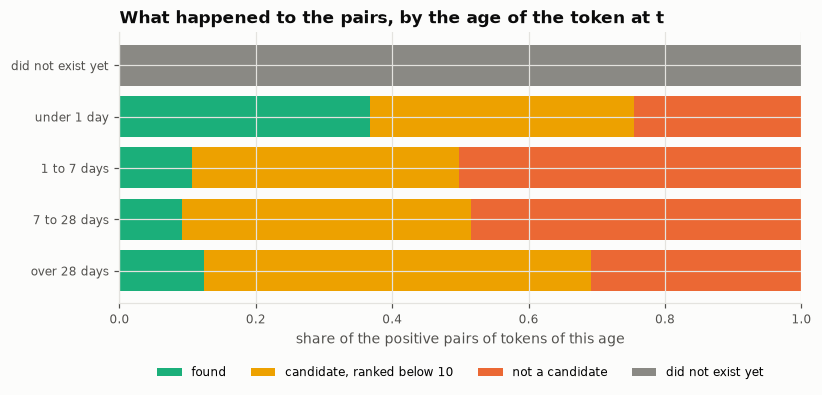

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.2))
left = np.zeros(len(age_order))
colours = {"found": plots.SERIES[2], "candidate, ranked below 10": plots.SERIES[3],
           "not a candidate": plots.SERIES[1], "did not exist yet": plots.BASELINE_GREY}  # fmt: skip
for outcome in ea.OUTCOMES:
    values = by_age[outcome].fillna(0).to_numpy()
    ax.barh(age_order, values, left=left, color=colours[outcome], label=outcome)
    left += values
ax.invert_yaxis()
ax.set_xlabel("share of the positive pairs of tokens of this age")
ax.set_title("What happened to the pairs, by the age of the token at t")
ax.legend(loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.32))
ax.grid(axis="x")
plt.show()

**The tokens missed most often**, over all 14 test points: the 15 tokens with the most missed pairs.

In [14]:
symbol = tokens.set_index("token_id")["symbol"]
by_token = pairs.groupby("token").agg(
    pairs=("hit", "size"), found=("hit", "sum"), cold_share=("cold", "mean"), window_users=("window_users", "median")
)
by_token["missed"] = by_token["pairs"] - by_token["found"]
by_token["symbol"] = by_token.index.map(symbol)
most_missed = by_token.sort_values("missed", ascending=False).head(15)
# cold_share: the share of the token's pairs at points where it did not exist yet (a token can be new at one point
# and established at a later one). window_users: median accounts in the 14-day window over those pairs.
most_missed[["symbol", "pairs", "found", "missed", "cold_share", "window_users"]]

,symbol,pairs,found,missed,cold_share,window_users
token,,,,,,
25383,0x7777…2bc8,1808,195,1613,0.0000,"1,276.0000"
2315,0x3b99…c256,1028,41,987,0.0000,135.0000
48,0xe0f6…c56c,1059,119,940,0.0000,"1,939.0000"
47470,0xb063…6904,961,22,939,0.8887,0.0000
45280,0xfe4d…eef9,1443,546,897,0.0326,755.0000
41158,0x7c5b…2f0c,896,34,862,0.0000,142.0000
49270,0xbeec…ed5f,1262,442,820,0.4120,885.0000
145,0x7f39…2ca0,1196,386,810,0.0000,"2,693.0000"
41,0x6874…2f38,1073,279,794,0.0000,"1,852.0000"


In [15]:
top = by_token.sort_values("pairs", ascending=False)
share_top10 = top["pairs"].head(10).sum() / top["pairs"].sum()
print(f"{len(by_token):,} distinct tokens were picked up. The 10 most picked hold {share_top10:.0%} of all pairs.")
print(f"Pairs of tokens picked up by a single account: {(by_token['pairs'] == 1).sum():,} "
      f"({by_token.loc[by_token['pairs'] == 1, 'pairs'].sum() / len(pairs):.0%} of all pairs).")  # fmt: skip

19,659 distinct tokens were picked up. The 10 most picked hold 6% of all pairs.
Pairs of tokens picked up by a single account: 7,966 (3% of all pairs).


**Accounts with many tokens.** Recall by history size in finer groups than in section 4.

In [16]:
user_parts = []
for t in pc.POINTS["test"]:
    task = pc.load_task(legs, t)
    per_user, _ = pc.evaluate_point(factory(task), task)
    user_parts.append(per_user.assign(point=t))
users = pd.concat(user_parts, ignore_index=True)
size_bins = [0, 1, 2, 4, 9, 19, np.inf]
size_labels = ["1", "2", "3–4", "5–9", "10–19", "20 or more"]
users["history"] = pd.cut(users["window_size"], size_bins, labels=size_labels)
by_history = users.groupby("history", observed=True).agg(accounts=("recall", "size"), recall=("recall", "mean"))
by_history.to_csv(OUT / "test_recall_by_history.csv")
by_history

,accounts,recall
history,,
1,26179,0.2096
2,14306,0.2021
3–4,15244,0.1993
5–9,16252,0.1079
10–19,10279,0.1050
20 or more,19826,0.0824


## 6. How much does the label depend on the length of the past? (open point 11.2)

A "returning" pair is one the account trades in the target window and had traded before $t$, but not in the 14
days before $t$. The plan's label does not count it as new; a 14-day label would. Points late in the data see more
past, so this share would grow over the points if it mattered.

In [17]:
share_rows = []
for part in ["dev_a", "dev_b", "test"]:
    for t in pc.POINTS[part]:
        share_rows.append({"part": part, **ea.returning_share(legs, pc.load_task(legs, t))})
returning = pd.DataFrame(share_rows)
returning.to_csv(OUT / "returning_share.csv", index=False)
returning.groupby("part")[["positives", "returning", "returning_share"]].mean()

,positives,returning,returning_share
part,,,
dev_a,"17,898.7000","1,241.7000",0.0741
dev_b,"18,086.0909","2,794.5455",0.1357
test,"21,418.4286","4,244.1429",0.1632


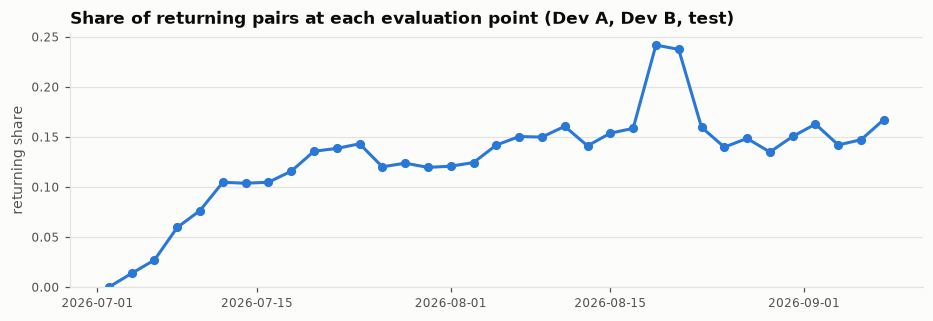

In [18]:
fig, ax = plt.subplots(figsize=(10, 3.0))
ax.plot(returning["point"], returning["returning_share"], marker="o", color=plots.SERIES[0])
ax.set_ylabel("returning share")
ax.set_ylim(bottom=0)
ax.set_title("Share of returning pairs at each evaluation point (Dev A, Dev B, test)")
plt.show()

## 7. Results from Dev B that were not part of the frozen set

The cold-start lists (notebook 13) and the ablation of the ranker (notebook 14) were measured on Dev B. They are not
repeated on the test, because they were not frozen as models; they are shown here so that the report has them in
one place.

In [19]:
pd.read_csv(pc.RESULTS_DIR / "wp6" / "ablation_dev_b.csv", index_col=0)

,recall,difference_from_all
all features,0.1460,0.0000
without popularity,0.1376,-0.0085
without neighbours,0.1049,-0.0412
without user,0.1442,-0.0018
without token,0.1481,0.0020
popularity only,0.1006,-0.0454


In [20]:
cold = pd.read_csv(pc.RESULTS_DIR / "wp5" / "refreshed_dev_b.csv")
cold.pivot_table(index="model", columns="refresh_hours", values=["recall", "cold_reached"], aggfunc="mean")

cold_reached                              \
refresh_hours                            1      3      6      12     48   
model                                                                     
baseline, refreshed                  0.0003 0.0002 0.0001 0.0000 0.0000   
feature mixed list                   0.1352 0.0563 0.0401 0.0230 0.0000   
mixed list                           0.1344 0.0578 0.0420 0.0254 0.0000   
newest-popular                       0.0742 0.0480 0.0360 0.0236 0.0000   
time-weighted blend, refreshed       0.1175 0.0439 0.0291 0.0134 0.0000   

                               recall                              
refresh_hours                      1      3      6      12     48  
model                                                              
baseline, refreshed            0.0959 0.0957 0.0952 0.0949 0.0936  
feature mixed list             0.1885 0.1705 0.1642 0.1551 0.1389  
mixed list                     0.1881 0.1709 0.1649 0.1561 0.1388  
newest-popular                 0.0387 0.0257 0.0213 0.0162 0.0081  
time-weighted blend, refreshed 0.1868 0.1712 0.1656 0.1567 0.1426

## 8. Reading

- **The success criterion is met.** The primary model (LambdaMART) beats the popularity baseline at all 14 test
  points: recall@10 0.154 against 0.108, a mean difference of +0.046 with a 95% interval of +0.038 to +0.055. The
  smallest single difference is +0.025 (4 September). All five frozen models beat the baseline at every point.
- **The gain carries over from Dev B almost unchanged.** Against the baseline: +0.052 on Dev B, +0.046 on the test
  for the primary model; +0.049 and +0.044 for the untimed fixed blend. The baseline itself is higher on the test
  (0.108 against 0.094), which the paired comparison absorbs.
- **The learned ranker does not beat the fixed combination** (research question 4). Against the untimed blend:
  +0.001, interval −0.003 to +0.007, 7 of 14 points; against the time-weighted blend +0.004, interval −0.001 to
  +0.008. The fading seen across Dev B did not turn into a loss, but there is no detectable gain either. The gain
  over the baseline comes from item neighbours combined with popularity (notebook 11); learning the combination
  adds nothing measurable.
- **Time weighting adds nothing on the test either** (research question 2): the time-weighted blend is 0.002 below
  the untimed one.
- **Where the gain is.** Every history group gains. Outside the popular head the baseline finds nothing by
  construction, and the models find 2–3% (the fixed blends 0.033, the primary model 0.028). Coverage rises from 0.2%
  of tokens to 2–4%.
- **Why pairs are missed** (pair-level shares, all 14 points): 29% of the positive pairs are tokens that did not
  exist at $t$; 23% are not among the ~680 candidates; 39% are candidates that the ranker placed below 10th; 9% are
  found. The largest single loss is in the ranking, not in the candidates.
- **By the age of the token:** tokens younger than a day at $t$ are found 37% of the time, far more often than
  older ones (9–12%). Tokens 1 to 28 days old are the weakest: half of their pairs are not even candidates.
- **Adoption is spread out.** 19,659 distinct tokens were picked up; the 10 most picked hold only 6% of the pairs.
  A short list can only cover a small part of this.
- **Accounts with long histories are hardest.** Recall falls from 0.21 (1 token) to 0.11 (5–9) and 0.08 (20 or
  more): they pick up more tokens, and each list has only 10 places.
- **The label and the length of the past (open point 11.2).** The share of returning pairs (traded before the
  14-day window, traded again in the target) rises from 0 at the first Dev A point to about 15% after a month and
  stays there (13–16%, with one spike to 24% on 19–21 August). The effect of the growing past is therefore
  concentrated in Dev A; Dev B and the test lie on the flat part, so the test comparison is not distorted by it.
  It is one more reason why Dev A numbers are not comparable with later ones.